In [36]:
import json
import os
import wordfreq
from collections import Counter
from wordfreq import top_n_list

current_file_path = os.path.dirname(os.getcwd())
json_path = os.path.join(current_file_path, 'word-counts.json')
low_eng_path = os.path.join(current_file_path, 'low-eng.json')
non_wiki_path = os.path.join(current_file_path, 'non-wiki-eng.json')
spanish_path = os.path.join(current_file_path, 'spanish.json')
polish_path = os.path.join(current_file_path, 'polish.json')

Zbiorę informacje na temat języków, dla analizy dla j. agnielskiego.
Wczytam dane z plików

In [64]:
with open(json_path, 'r') as file:
    long_article_dict = json.load(file)
    long_article_dict = dict(sorted(long_article_dict.items(), key=lambda item: -item[1]))
with open(low_eng_path, 'r') as file:
    low_f_dict = json.load(file)
    low_f_dict = dict(sorted(low_f_dict.items(), key=lambda item: -item[1]))
with open(spanish_path, 'r') as file:
    spanish_dict = json.load(file)
    spanish_dict = dict(sorted(spanish_dict.items(), key=lambda item: -item[1]))
    print(spanish_dict)
with open(non_wiki_path, 'r') as file:
    english_non_wiki = json.load(file)
    english_non_wiki = dict(sorted(english_non_wiki.items(), key=lambda item: -item[1]))
with open(polish_path, 'r') as file:
    polish_dict = json.load(file)
    polish_dict = dict(sorted(polish_dict.items(), key=lambda item: -item[1]))

k = 1000
top_k_list_eng = top_n_list('en', k)
top_k_list_esp = top_n_list('es', k)
top_k_list_pol = top_n_list('pl', k)

{'de': 187, 'geralt': 93, 'la': 92, 'en': 84, 'a': 79, 'y': 73, 'que': 68, 'el': 57, 'un': 50, 'los': 47, 'the': 42, 'por': 39, 'del': 37, 'witcher': 32, ',': 29, 'su': 29, 'una': 28, 'se': 26, 'lo': 24, 'con': 24, 'es': 21, 'como': 21, 'para': 21, 'of': 20, 'rivia': 19, '.': 19, 'fue': 14, 'no': 14, 'las': 12, 'sus': 12, 'al': 11, 'brujo': 10, 'era': 10, 'más': 10, 'durante': 9, 'triss': 8, 'brujos': 8, 'después': 8, 'pero': 8, 'serie': 8, 'lobo': 7, 'entrada': 7, 'diario': 7, 'mundo': 7, 'él': 7, 'o': 7, ')': 6, 'and': 6, 'otros': 6, 'también': 6, 'conocido': 6, 'vesemir': 6, '2:': 6, 'assassins': 6, 'kings': 6, 'hombre': 6, 'gran': 6, 'ser': 6, 'modelo': 6, 'witcher:': 6, 'escuela': 5, 'habilidades': 5, 'merigold': 5, 'le': 5, 'kaer': 5, 'opción': 5, 'muy': 5, 'game': 5, 'largo': 5, 'ya': 5, 'debido': 5, 'sin': 5, 'uno': 5, 'parte': 5, 'netflix': 5, 'cómic': 5, '(': 4, 'blood': 4, 'wine': 4, 'visenna': 4, 'yennefer': 4, 'ciri': 4, 'apariciones': 4, 'pesar': 4, 'cazador': 4, 'este': 

Zdefiniuję funkcję

In [38]:
def f(slowa_w_tekscie, slowa_w_jezyku, k):
    k_dostosowane = min(k, min(len(slowa_w_tekscie), len(slowa_w_jezyku)))
    slowa_w_jezyku = list(slowa_w_jezyku)
    slowa_w_tekscie = list(slowa_w_tekscie)
    slowa_w_jezyku = slowa_w_jezyku[:k_dostosowane]
    slowa_w_tekscie = slowa_w_tekscie[:k_dostosowane]
    ret = sum([1 if slowo_z_tekstu in slowa_w_jezyku else 0
               for slowo_z_tekstu in slowa_w_tekscie]) / k_dostosowane * 100
    return ret

In [71]:
k_range = [3, 10, 100, 1000]
languages = [top_k_list_eng, top_k_list_esp, top_k_list_pol]
wyniki = []
for i in range (0, len(languages)):
    lang = languages[i]
    wyniki.append([])
    for j in range (0, len(k_range)):
        k_case = k_range[j]
        f_1_long_art = f(long_article_dict, lang, k_case)
        f_2_eng_low = f(low_f_dict, lang, k_case)
        f_3_non_wiki = f(english_non_wiki, lang, k_case)
        f_4_spanish = f(spanish_dict, lang, k_case)
        f_5_polish = f(polish_dict, lang, k_case)
        y = [f_1_long_art, f_2_eng_low, f_3_non_wiki, f_4_spanish, f_5_polish]
        wyniki[i].append(y)
print(wyniki)
wyniki_eng = wyniki[0]
wyniki_pol = wyniki[2]
wyniki_esp = wyniki[1]

[[[33.33333333333333, 0.0, 66.66666666666666, 0.0, 0.0], [50.0, 30.0, 70.0, 10.0, 10.0], [40.0, 14.000000000000002, 39.0, 5.0, 6.0], [24.6, 24.5, 31.058823529411768, 3.2, 3.0]], [[0.0, 0.0, 0.0, 66.66666666666666, 0.0], [0.0, 0.0, 10.0, 90.0, 0.0], [2.0, 2.0, 1.0, 43.0, 2.0], [3.9, 4.3999999999999995, 3.058823529411765, 28.799999999999997, 1.9]], [[0.0, 0.0, 0.0, 0.0, 66.66666666666666], [20.0, 0.0, 10.0, 0.0, 70.0], [23.0, 2.0, 5.0, 4.0, 39.0], [19.1, 4.3, 4.470588235294118, 2.5, 25.900000000000002]]]


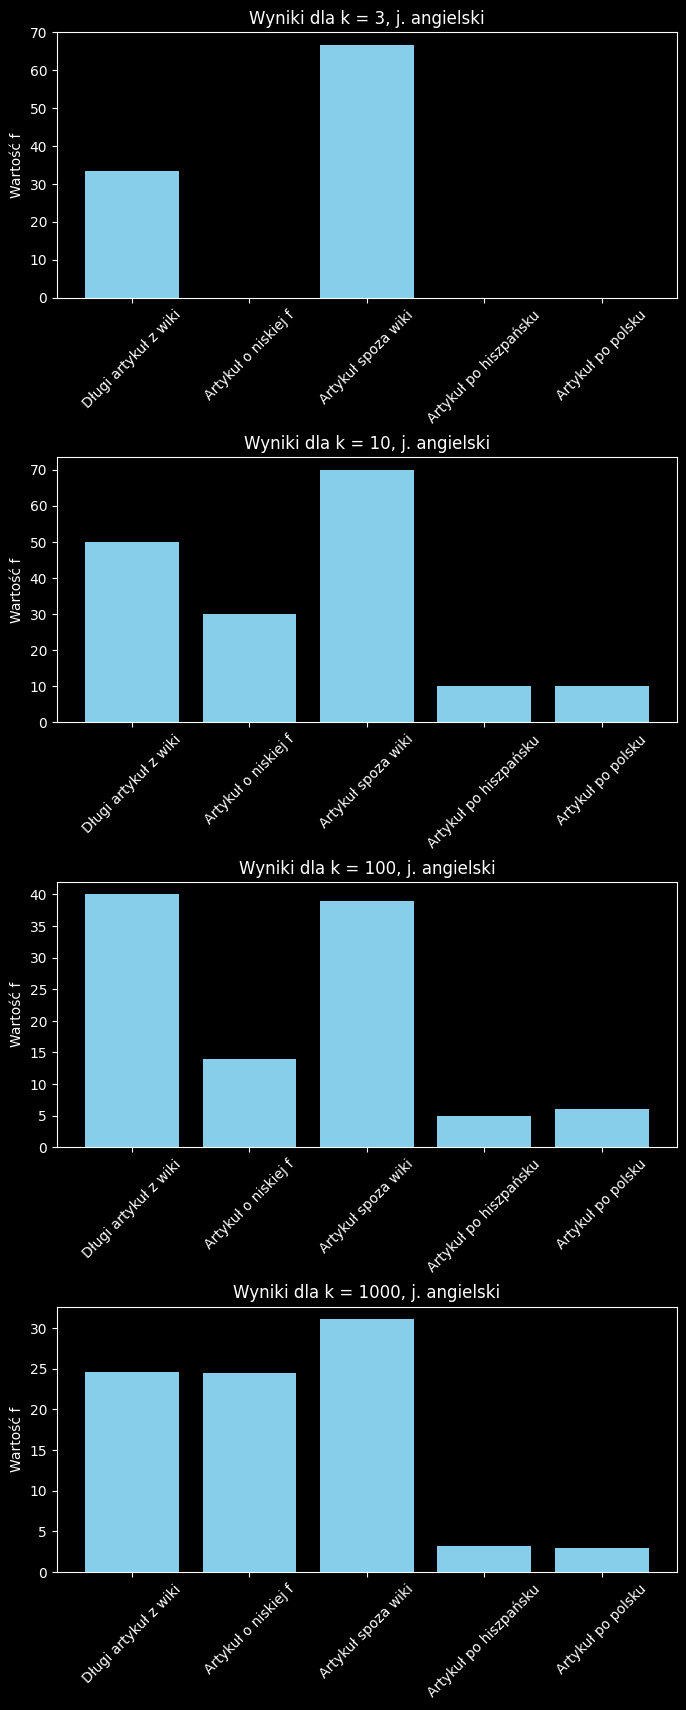

In [73]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(len(wyniki_eng), 1, figsize=(8, 20))
x_podpisy = ['Długi artykuł z wiki', 'Artykuł o niskiej f', 'Artykuł spoza wiki', 'Artykuł po hiszpańsku', 'Artykuł po polsku']

for i in range(0, len(wyniki[0])):
    axs[i].bar(x_podpisy, wyniki_eng[i], color='skyblue')
    axs[i].set_title(f"Wyniki dla k = {k_range[i]}, j. angielski")
    axs[i].set_ylabel("Wartość f")
    axs[i].tick_params(axis='x', rotation=45)

plt.subplots_adjust(hspace=0.6)
plt.show()

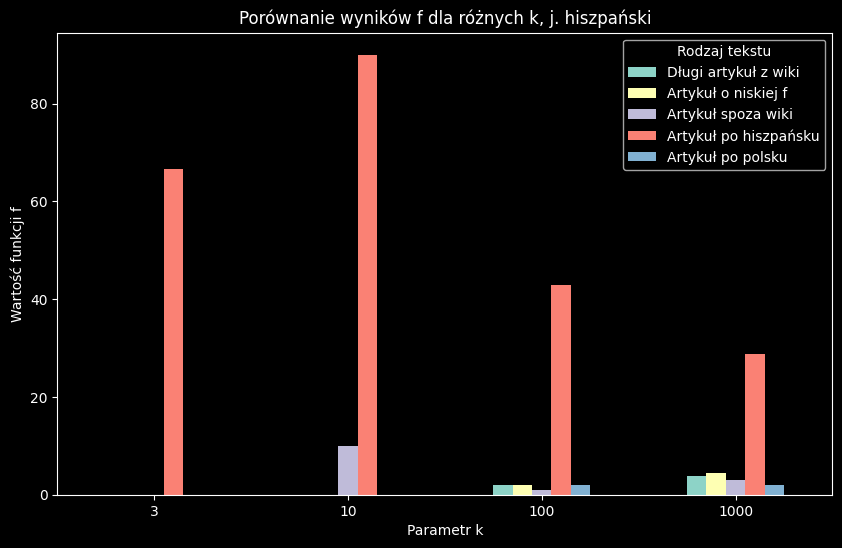

In [74]:
import pandas as pd
k_range = ['3', '10', '100', '1000']
x_podpisy = ['Długi artykuł z wiki', 'Artykuł o niskiej f', 'Artykuł spoza wiki', 'Artykuł po hiszpańsku', 'Artykuł po polsku']

df = pd.DataFrame(wyniki[1], index=k_range, columns=x_podpisy)

df.plot(kind='bar', figsize=(10, 6))

plt.title("Porównanie wyników f dla różnych k, j. hiszpański")
plt.ylabel("Wartość funkcji f")
plt.xlabel("Parametr k")
plt.legend(title="Rodzaj tekstu")
plt.xticks(rotation=0)
plt.show()

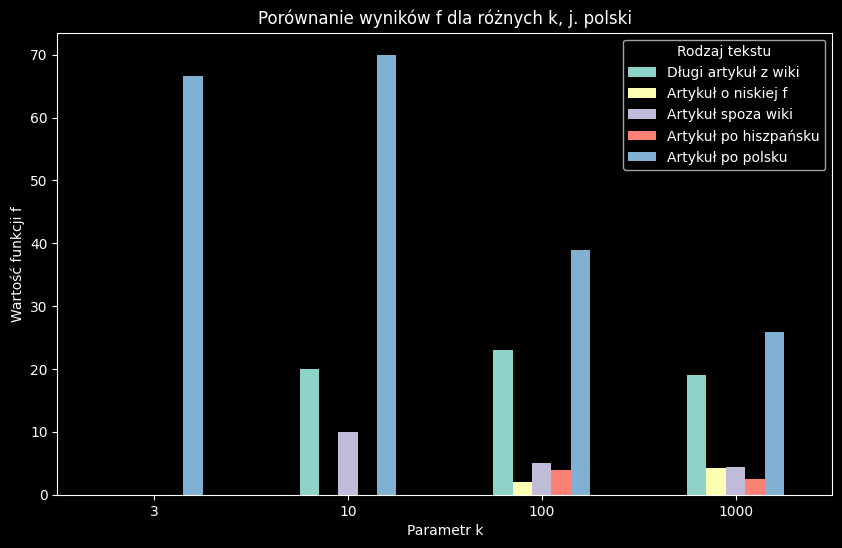

In [75]:
import pandas as pd
k_range = ['3', '10', '100', '1000']
x_podpisy = ['Długi artykuł z wiki', 'Artykuł o niskiej f', 'Artykuł spoza wiki', 'Artykuł po hiszpańsku', 'Artykuł po polsku']

df = pd.DataFrame(wyniki[2], index=k_range, columns=x_podpisy)

df.plot(kind='bar', figsize=(10, 6))

plt.title("Porównanie wyników f dla różnych k, j. polski")
plt.ylabel("Wartość funkcji f")
plt.xlabel("Parametr k")
plt.legend(title="Rodzaj tekstu")
plt.xticks(rotation=0)
plt.show()

In [ ]:
# OPIS WYNIKÓW
# Bardzo prosta funkcja, którą zastosowałem, wydaje się być całkiem skuteczna w przewidywaniu języka, w którym został napisany tekst.
# Co istotne, funkcja rzeczywiście radzi sobie lepiej przy dużej ilości tekstu. Co prawda dopasowanie bezwzględne spada, jednak kontrast między pewnością dla różnych języków rośnie, co pozwala na jednoznaczne odróżnienie języka.
# Co ciekawe, funkcja wydaje się być użyteczna nawet dla k równego 3.
# Dobór języków okazał się być istotny - funkcja poradziła sobie znacznie gorzej z językiem polskim. Dla k = 1000 zaobserwowano dopasowanie na poziomie ok. 25, co jest tylko trochę wyższe od pewności dla tekstu w j. agnielskim. Prawdopodobnie niska pewność co do j. polskiego wynika z wielu form i odmian najczęściej używanych słów.
# Znalezienie artykułu o niskim wyniku f było umiarkowanie trudne. Przyjąłem strategię aby szukać tekstu jak najkrótszego (powyżej 20) słów, co maksymalizowało szanse na nierównomierny rozkład słów i dzięki temu niskie dopasowanie. Jednak dla k = 1000, funkcja wciąż zdołała poprawnie dopasować tekst. Wydaje mi się, że gdyby udało się znaleźć tekst o długości między 20 a 30 znaków, jego dopasowanie byłoby około jeszcze połowę niższe.